# ORIE 5355/INFO 5370 HW 3: Algorithmic Pricing

 - Name: Zoe Krishtul
 - Net-id: ZRK7
 - Date: 12/13/26
 - Late days used for this assignment: 0
 - Total late days used (counting this assignment): 0
 - People with whom you discussed this assignment: N/A

## Notes

We have marked questions in <span style='color: green;'>green</span>. Please put answers in the default color. You'll want to write text answers in "markdown" mode instead of code. In Jupyter notebook, you can go to Cell > Cell Type > Markdown, from the menu. Please carefully read the late days policy and grading procedure [here](https://orie5355.github.io/Fall_2026/assignments/). In that link, we also give some tips on exporting your notebook to PDF, which is required for GradeScope submission. 

Some of the questions can be interpreted in multiple ways. That is always true in data science. You'll need to make judgment calls for what analysis to do. For the homework, you'll still receive full points for any "reasonable" choice. Briefly explain and justify your choices. Also feel free to ask questions on EdStem. 

## Disclosure and survey

<span style='color: green;'> Type "I understand" in the next box to attest to the following statements.</span>

I understand that I have to submit this homework assignment in two places:

 - gradescope -- where I will submit a pdf of the assignment and tag each page of my assignment with the problem to which it corresponds.
 - github (via classroom50) -- where I will commit and push up this notebook and the rest of my code, in a runnable format. 

 I understand that I will reach out to the teaching staff via office hours or EdStem at least 5 days before the homework is due if I have any issues submitting the assignment on either of these platforms, such as I am not on the class roster. I understand that I may receive points off (up to full value of the homework assignment) if I do not submit to both locations. 

 I understand that the teaching staff prefers that I make multiple commits on github (via classroom50) as I am completing the assignment (for example, after I finish each problem), and that this information may be used to assess overall understanding, progress, and qualitative assessment/grading.

 I understand that I must fully disclose my usage of AI in the box below **and** at the top of each problem. I will follow the AI usage policy, and am responsible for everything that I submit. I understand that quizzes and other assessments may evaluate understanding of what I submitted, including asking me to interpret what code does.

I understand

<span style='color: green;'>After you finish the homework, please complete the following (short, anonymous) post-homework </span>[survey](https://forms.gle/M8TRBVqjqMfoaXXo6)<span style='color: green;'> and include the survey completion code below.</span>

<span style='color: green;'> AI disclosure. In the below box, please write 1-3 sentences about your use of AI in the assignment </span>**overall**<span style='color: green;'>. Example responses include:</span>

- None
- "I vibe-coded all the code for the assignment. I didn't even try to understand or parse the code"
- "I referred to ChatGPT for interpreting parts of the assignment, and to help me write code, but ultimately I understood each of its outputs and either typed/copied in small pieces code that it gave me. I wrote more than half the code myself". 

Note that AI disclosure is part of the grade for each component, and you are ultimately responsible for your learning.

 **Please also note that AI disclosure is part of each question below**

# Conceptual component [4 points]

<span style='color: green;'>AI disclosure for this conceptual component: In the next box, describe any AI use for this conceptual component and how it was used, or write "None".</span>

None

Please complete the following pricing ethics scenario questionnaire: https://forms.gle/Bahbqcn9126u3DzM7, and include the survey completion code below. **We will discuss these issues in class on 10/19. You must complete the questionnaire before the day of that class, even if you turn in the rest of the homework later. The questionnaire will close the morning of the class that we discuss these issues.**

<span style='color: green;'>Survey completion code: </span>

 hw3_pricingethics_2021

<span style='color: green;'>Based on the first letter of your first name, explain your answers to the following questions, in at most three sentences each.</span>

First letter A-C: 1, 6, 11, 16

First letter D-H: 2, 7, 12, 17

First letter I-M: 3, 8, 13, 18

First letter N-S: 4, 9, 14, 19

First letter T-Z: 5, 10, 15, 20


<span style='color: green;'>Give and discuss your answers for the 4 questions in this notebook, to be turned in with the rest of the homework. Also be prepared to discuss your answers to at least these questions in class (I might randomly call on people), but you should also be willing/able to discuss your answers to other questions. </span>

5: completely fair
The grocer is increasing the price due to higher wholesale cost and is not trying to profit off of the shortage. I believe it is completely fair for a business to increase cost for customers when they themselves have to pay more for the product.

10: completely fair
The landlord is adjusting rent based on the prices of surrounding properties. I belive it is completely fair to adjust prices to match the current market, especially since this increase in price isn't based on anything related to the tenant.

15: acceptable
I think this scenario is acceptable because people in wealthier neighborhoods are overall more capable of affording higher prices. However, I wouldn't consider it 100% fair since the algorithm is making assumptions based on where someone is living rather than their actual financial situation.

20: unfair
Even though the algorithm is not using race or ethnicity to make the call, it could still indirectly discriminate using related variables. I believe it is unfair if someone's access to a loan is influenced by demographic rather than their financial situation.

# Programming component

## Helper code

In [70]:
import numpy as np
import pandas as pd
import os, sys, math
import matplotlib.pyplot as plt

In [71]:
df_train = pd.read_csv('HW3_data_train.csv')
test_demand_curve = pd.read_csv('test_demand.csv')

In [72]:
df_train.head()

,Location,Income,Offered price,Purchased
0,Africa,10.38,3.16,False
1,Europe,26.33,3.47,True
2,Europe,24.06,3.78,True
3,Africa,16.18,3.74,False
4,Asia Pacific,13.73,4.75,False


In [73]:
df_train.shape, test_demand_curve.shape

((4000, 4), (199, 5))

## Problem 1: Demand estimation and pricing without covariates

<span style='color: green;'>AI disclosure for this problem: In the next box, describe any AI use for this problem and how it was used, or write "None".</span>

I used ChatGPT to help write and debug portions of the code. I used AI to explain logic behind functions and concepts I did not understand.

First, we will use the training data to construct estimates of the demand at each price without leveraging the covariates, and then use that estimated function to calculate optimal prices. 

### 1a) Naive method: empirical estimate of demand $d(p)$ at each price

<span style='color: green;'>Fill in the below function, that takes in a dataframe and the number of bins into which to separate the historical prices. The function should output a dataframe that has one row for each price bin, with two columns: the bin interval, and the estimated demand </span>$d(p)$<span style='color: green;'> (the fraction of potential customers who purchase at price </span>$p$<span style='color: green;'>) in that bin.  </span>
    
Use the following function to create bins:
https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.qcut.html

In [74]:
# Example with 10 bins:
df_train['bin_with_10_bins'] = pd.qcut(df_train['Offered price'], 10)
df_train.head()

,Location,Income,Offered price,Purchased,bin_with_10_bins
0,Africa,10.38,3.16,False,"(2.95, 3.54]"
1,Europe,26.33,3.47,True,"(2.95, 3.54]"
2,Europe,24.06,3.78,True,"(3.54, 4.19]"
3,Africa,16.18,3.74,False,"(3.54, 4.19]"
4,Asia Pacific,13.73,4.75,False,"(4.19, 4.77]"


For example, with 2 bins and passing in df_train to the function, you should see the following output:

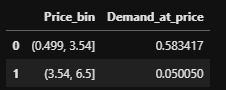

(If you can't see the image, then it is an image with 2 columns (Price_bin and Demand_at_price), and two rows. The First row has price bin (0.499, 3.54] and Demand_at_price equal to .583.)

In [75]:
def create_empirical_estimate_demand_df(df, number_of_pricing_bins):
    df = df.copy()
    df['Price_bin'] = pd.qcut(df['Offered price'], number_of_pricing_bins)
    
    empirical_df = df.groupby('Price_bin', observed=True)['Purchased'].mean() 
    
    empirical_df = empirical_df.reset_index()
    empirical_df = empirical_df.rename(columns={'Purchased': 'Empirical Demand Estimate'})
    return empirical_df

<span style='color: green;'>Fill in the below function, that takes in a single price and your empirical df from the above function and outputs the prediction for the demand </span>$d(p)$<span style='color: green;'> at that price. For example, with 2 bins, at price = 3 the function should output 0.583417.</span>

If the price is lower than the smallest bin, then use the value of the smallest bin. If it is higher than the highest bin, use the value of the highest bin.

In [76]:
def get_prediction_empirical(empirical_df, price):
    # prices below lowest bin
    if price <= empirical_df['Price_bin'].iloc[0].left:
        return empirical_df['Empirical Demand Estimate'].iloc[0]
    
    # prices above highest bin
    if price > empirical_df['Price_bin'].iloc[-1].right:
        return empirical_df['Empirical Demand Estimate'].iloc[-1]
    
    # bin with price in it
    for _, row in empirical_df.iterrows():
        interval = row['Price_bin']

        if interval.left < price <= interval.right:
            return row['Empirical Demand Estimate']

In [77]:
prices_to_predict = np.linspace(min(df_train['Offered price']), max(df_train['Offered price']), 200)

<span style='color: green;'>Plot in a single figure the outputs of your function as a line plot -- where the X axis corresponds to prices in `prices_to_predict` and the Y axis the predicted Demand at that price -- for the following three inputs to the function:</span>
    
    1. the dataframe is the first 100 rows of df_train, with 10 bins.
    
    2. the dataframe is the first 500 rows of df_train, with 10 bins.
    
    3. the dataframe is all the rows of df_train, with 10 bins.

<span style='color: green;'>In the same figure, include the "true" test-time demand curve, using `test_demand_curve` that we loaded at the top of the homework -- plot the mid-point of each bin on the X axis, and the demand for that bin on the Y axis. So your plot will contain 4 curves in total.
</span>

In [78]:
empirical_100 = create_empirical_estimate_demand_df(df_train.iloc[:100], 10)
empirical_500 = create_empirical_estimate_demand_df(df_train.iloc[:500], 10)
empirical_all = create_empirical_estimate_demand_df(df_train, 10)

predictions_100 = []

for price in prices_to_predict:
    prediction = get_prediction_empirical(empirical_100, price)
    predictions_100.append(prediction)

predictions_500 = []

for price in prices_to_predict:
    prediction = get_prediction_empirical(empirical_500, price)
    predictions_500.append(prediction)

predictions_all = []

for price in prices_to_predict:
    prediction = get_prediction_empirical(empirical_all, price)
    predictions_all.append(prediction)

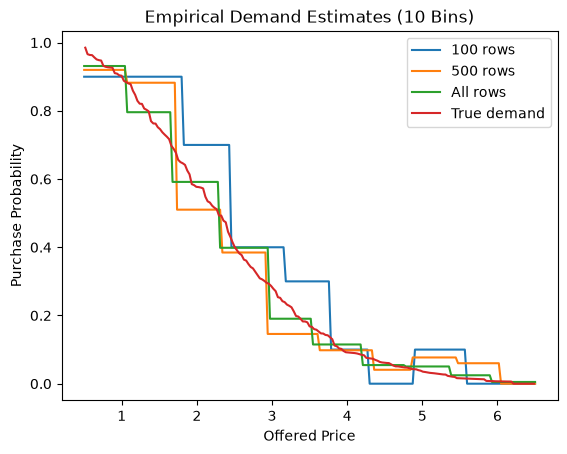

In [79]:
plt.plot(prices_to_predict, predictions_100, label='100 rows')
plt.plot(prices_to_predict, predictions_500, label='500 rows')
plt.plot(prices_to_predict, predictions_all, label='All rows')
plt.plot(test_demand_curve['Price_bin_mid'], test_demand_curve['Demand_at_price'], label='True demand')

plt.xlabel('Offered Price')
plt.ylabel('Purchase Probability')
plt.title('Empirical Demand Estimates (10 Bins)')
plt.legend()
plt.show()

<span style='color: green;'>Do the same plot, except now you're using 50 bins for each of the three data frames.</span>

In [80]:
empirical_100_50 = create_empirical_estimate_demand_df(df_train.iloc[:100], 50)
empirical_500_50 = create_empirical_estimate_demand_df(df_train.iloc[:500], 50)
empirical_all_50 = create_empirical_estimate_demand_df(df_train, 50)

predictions_100_50 = []

for price in prices_to_predict:
    prediction = get_prediction_empirical(empirical_100_50, price)
    predictions_100_50.append(prediction)

predictions_500_50 = []

for price in prices_to_predict:
    prediction = get_prediction_empirical(empirical_500_50, price)
    predictions_500_50.append(prediction)

predictions_all_50 = []

for price in prices_to_predict:
    prediction = get_prediction_empirical(empirical_all_50, price)
    predictions_all_50.append(prediction)

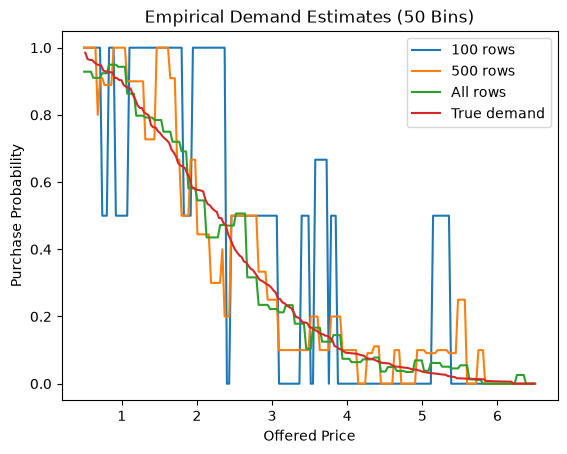

In [81]:
plt.plot(prices_to_predict, predictions_100_50, label='100 rows')
plt.plot(prices_to_predict, predictions_500_50, label='500 rows')
plt.plot(prices_to_predict, predictions_all_50, label='All rows')
plt.plot(test_demand_curve['Price_bin_mid'], test_demand_curve['Demand_at_price'], label='True demand')

plt.xlabel('Offered Price')
plt.ylabel('Purchase Probability')
plt.title('Empirical Demand Estimates (50 Bins)')
plt.legend()
plt.show()

<span style='color: green;'>Comment on your output in no more than 3 sentences. What is the effect of using more data and more bins?</span>

Using more data makes our estimates closer to the true demand curve because a larger sample size gives us more reliable estimates. Increasing the number of bins makes the estimates more detailed but also more volatile, especially when there are fewer observations per bin.

### 1b) Demand estimation using logistic regression

<span style='color: green;'>First, Fill in the below function that fits a logistic regression to predict the probability of purchase at a price (</span>$d(p)$<span style='color: green;'>). The logistic regression should just have two coefficients: one for the intercept, and one for the price. The function takes in a dataframe that you will use as your training data for your model, and should return your fitted model. </span>

Note: the "intercept" term corresponds to a column of all 1s in your dataframe. If you do logistic regression in statsmodels, you can have it add the intercept term for you if you use the formula feature. In sklearn, there is a parameter called fit_intercept. 

In [82]:
from sklearn.linear_model import LogisticRegression

def fit_logistic_regression_demand_just_on_price(df):
    x = df[['Offered price']]
    y = df['Purchased']

    model = LogisticRegression()
    model.fit(x, y)

    return model

<span style='color: green;'>Fill in the below function, that takes in a single price and your trained model and outputs the prediction for the demand </span>$d(p)$<span style='color: green;'> at that price.</span>

Return the predicted probability of `Purchased=True` (equivalently, 1), not a binary class prediction. With scikit-learn, use `fitted_model.predict_proba(X)` and select the column for the `True`/1 class, checking `fitted_model.classes_`. With a fitted statsmodels logistic model, use `fitted_model.predict(X)` to obtain purchase probabilities. In both cases, construct the prediction inputs consistently with the model you fitted, including the intercept where required.

In [83]:
def get_prediction_logistic(fitted_model, price):
    X_new = pd.DataFrame({'Offered price': [price]})
    
    probabilities = fitted_model.predict_proba(X_new)
    purchase_index = list(fitted_model.classes_).index(True)

    return probabilities[0][purchase_index]

<span style='color: green;'>For each of the three training dataframes as in part A, fit a model and get the predictions for each of the prices in `prices_to_predict` using your above function. Generate the same lineplot as above. Also include the "true" test-time demand curve, `test_demand_curve`. </span>

In [84]:
print(df_train['Offered price'].min())
print(df_train['Offered price'].max())

0.5
6.5


In [85]:
model_100 = fit_logistic_regression_demand_just_on_price(df_train.iloc[:100])
model_500 = fit_logistic_regression_demand_just_on_price(df_train.iloc[:500])
model_all = fit_logistic_regression_demand_just_on_price(df_train)

prices_to_predict = np.linspace(0.5, 6.5, 200)

predictions_100 = [get_prediction_logistic(model_100, price) for price in prices_to_predict]
predictions_500 = [get_prediction_logistic(model_500, price) for price in prices_to_predict]
predictions_all = [get_prediction_logistic(model_all, price) for price in prices_to_predict]

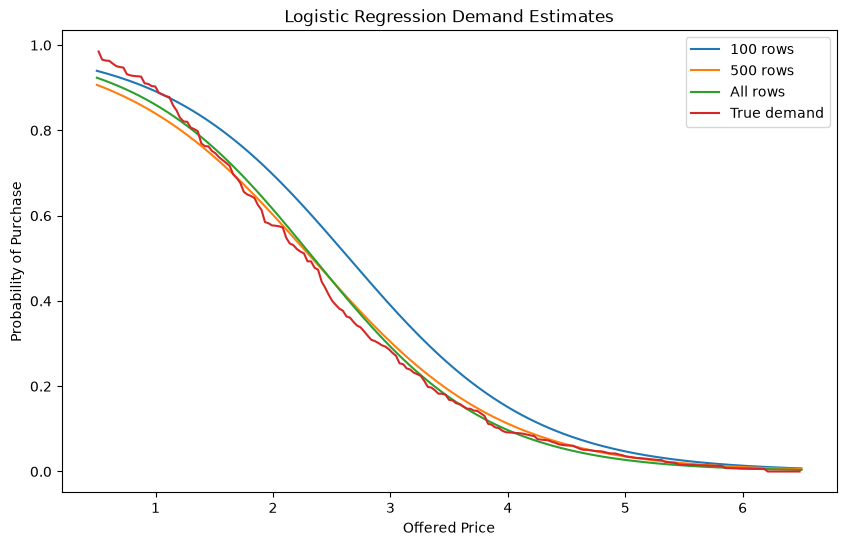

In [86]:
plt.figure(figsize=(10, 6))

plt.plot(prices_to_predict, predictions_100, label='100 rows')
plt.plot(prices_to_predict, predictions_500, label='500 rows')
plt.plot(prices_to_predict, predictions_all, label='All rows')

plt.plot(test_demand_curve['Price_bin_mid'], test_demand_curve['Demand_at_price'], label='True demand',)

plt.xlabel('Offered Price')
plt.ylabel('Probability of Purchase')
plt.title('Logistic Regression Demand Estimates')
plt.legend()
plt.show()

<span style='color: green;'>Comment on your output in no more than 3 sentences. What is the effect of using logistic regression instead of the empirical distribution? </span>

The logistic regression produced a smoother curve than the empirical method because it follows the relationship between price and purchase probability. It does not estimate demand separately for each bin. For 100 observations, the model overestimated, with 500 and all, the estimates were pretty close to the true demand curve. The logistic regression seems to work better with small datasets, the estimates are not as volatile.

### 1c) Optimal pricing using your demand estimates

For this part, use 10 bins for each empirical model and use `prices_to_predict` as the candidate-price grid for every model and the supplied test curve. Here, "optimal" means the best price on this grid, not the best price over all real numbers. If multiple prices maximize revenue, choose the smallest. Use the same grid and test-curve lookup convention in Problem 2b.

To evaluate a supplied test curve at price $p$, use `Demand_at_price` from the row with `Price_bin_left < p <= Price_bin_right`. At or below the smallest left endpoint, use the first row; above the largest right endpoint, use the last row. Treat demand as constant within each bin; do not interpolate between bin midpoints.

<span style='color: green;'>Fill in the following function that takes in two lists: a list of prices, and a list of predicted demand d(p) at that price. The function outputs the revenue maximizing price given the data and the corresponding revenue. You may use a "brute force" technique, that loops through all the possible prices and calculates the revenue using that price. </span>

In [87]:
def get_revenue_maximizing_price_and_revenue(price_options, demand_predictions):
    revenues = []
    
    for price, demand in zip(price_options, demand_predictions):
        revenue = price * demand
        revenues.append(revenue)

    best_index = np.argmax(revenues)
    best_price = price_options[best_index]
    best_revenue = revenues[best_index]

    return best_price, best_revenue

<span style='color: green;'>Print out the optimal price and the predicted optimal revenue from the predictions for your naive and logistic models, using 100 rows and all the data, each. </span>

For example, we got the following:

logistic, 100 points:  2.580402010050251 1.2143341610705582

naive, all points:  2.278894472361809 1.348157868550674

Note: last year, people reported different numbers for the logistic regression based on the exact package they used (which might, for example, have different default solvers or default parameters. If you get a different number, that's fine, as long as your methods are correct.) For example, with scikit-learn, people last year reported getting: (2.1884422110552766, 1.4070878495510661) for the logistic regression with 100 rows. 

In [88]:
print("Logistic, 100 rows:", get_revenue_maximizing_price_and_revenue(prices_to_predict, predictions_100))
print("logistic, all rows:", get_revenue_maximizing_price_and_revenue(prices_to_predict, predictions_all))

naive_100 = create_empirical_estimate_demand_df(df_train.iloc[:100], 10)
naive_all = create_empirical_estimate_demand_df(df_train, 10)

naive_predictions_100 = [get_prediction_empirical(naive_100, price) for price in prices_to_predict]
naive_predictions_all = [get_prediction_empirical(naive_all, price) for price in prices_to_predict]

print("Naive, 100 rows:", get_revenue_maximizing_price_and_revenue(prices_to_predict, naive_predictions_100))
print("Naive, all rows:", get_revenue_maximizing_price_and_revenue(prices_to_predict, naive_predictions_all))

Logistic, 100 rows: (np.float64(2.1884422110552766), np.float64(1.4074807934709683))
logistic, all rows: (np.float64(1.9773869346733668), np.float64(1.2299587530420741))
Naive, 100 rows: (np.float64(2.42964824120603), np.float64(1.700753768844221))
Naive, all rows: (np.float64(2.278894472361809), np.float64(1.348157868550674))


<span style='color: green;'>Now, we're going to use the "true" test-time demand curve, `test_demand_curve`. For each of the above predicted optimal prices, calculate the revenue resulting from that price used on the true demand curve. Also print out the true optimal price and corresponding revenue for that curve on `prices_to_predict`, using the bin-lookup convention above.  </span>

For example, we got:

true revenue using logistic 100 price:  0.9729384628058323

(Again, you might get a slightly different number, depending on how you implemented your code. That's OK.)

In [89]:
def get_true_demand(price):
    # find bin with this price
    matching = test_demand_curve[(test_demand_curve['Price_bin_left'] < price) & (price <= test_demand_curve['Price_bin_right'])]
    
    if not matching.empty:
        return matching['Demand_at_price'].iloc[0]

    # prices below lowest bin
    if price <= test_demand_curve['Price_bin_left'].min():
        return test_demand_curve['Demand_at_price'].iloc[0]

    # prices above highest bin
    if price > test_demand_curve['Price_bin_right'].max():
        return test_demand_curve['Demand_at_price'].iloc[-1]

In [90]:
logistic_100_price, _ = get_revenue_maximizing_price_and_revenue(prices_to_predict, predictions_100)

true_revenue_at_logistic_100_price = logistic_100_price * get_true_demand(logistic_100_price)

models = {"Logistic, 100 rows": predictions_100, "Logistic, all rows": predictions_all, "Naive, 100 rows": naive_predictions_100, "Naive, all rows": naive_predictions_all}

for name, predictions in models.items():
    best_price, _ = get_revenue_maximizing_price_and_revenue(prices_to_predict, predictions)
    
    true_revenue = best_price * get_true_demand(best_price)
    
    print(name, "True revenue at best price:", true_revenue)

true_predictions = [get_true_demand(price) for price in prices_to_predict]

true_optimal_price, true_optimal_revenue = get_revenue_maximizing_price_and_revenue(prices_to_predict, true_predictions)

print("True optimal price:", true_optimal_price)
print("True optimal revenue:", true_optimal_revenue)

Logistic, 100 rows True revenue at best price: 1.141795936202753
Logistic, all rows True revenue at best price: 1.1413105797443595
Naive, 100 rows True revenue at best price: 1.082112241881677
Naive, all rows True revenue at best price: 1.1655414476964976
True optimal price: 2.0979899497487438
True optimal revenue: 1.2008231949219783


<span style='color: green;'>How do your estimates compare to the actual revenue? Discuss in no more than 3 sentences. </span>

All four models overestimated the predicted revenue. The naive model with all of the data performed best. The naive model with 100 rows did the worst. This proves that even when a model predicts high revenue, it does not always mean it will choose the best price.

# Problem 2: Demand estimation and pricing with covariates 

<span style='color: green;'>AI disclosure for this problem: In the next box, describe any AI use for this problem and how it was used, or write "None".</span>

Now, we are going to ask you to do personalized pricing, based on just two binary covariates. 

First, compute the median `Income` using all of `df_train`. Create a wealth indicator: `0` (`LowWealth`) if `Income` is at or below this median, and `1` (`HighWealth`) if `Income` is strictly above it. Keep this cutoff fixed when making predictions. Second, create a location indicator: `1` (`America`) if the location is America, and `0` (`NotAmerica`) otherwise.

For this section, we will use all the `df_train` data, as opposed to just the first few rows. Write $x$ for the pair of binary covariates, and $d(p,x)$ for the probability of purchase at price $p$ for a customer with covariates $x$.

### 2a) Demand estimation

<span style='color: green;'>First, fill in the below function that fits a logistic regression to predict the probability of purchase </span>$d(p,x)$<span style='color: green;'>. Retain the intercept and offered-price predictor from Problem 1, and add one coefficient for each of the two binary covariates. You may also add interactions, including interactions between price and covariates. If you add more interactions, you may wish to add regularization. </span>

In [91]:
median_income = df_train['Income'].median()

df_train['Wealth'] = (df_train['Income'] > median_income).astype(int)
df_train['America'] = (df_train['Location'] == 'America').astype(int)

In [92]:
def fit_logistic_regression_demand_with_covariates(df):
    X = df[['Offered price', 'Wealth', 'America']]
    y = df['Purchased']
    model = LogisticRegression()
    model.fit(X, y)
    return model

<span style='color: green;'>Fill in the below function, that takes in a single price, covariates, and your trained model, and outputs the prediction for the demand </span>$d(p,x)$<span style='color: green;'> at that price. For example, one covariate combination is `['NotAmerica', 'LowWealth']`; encode its indicators consistently with your fitted model.</span>

In [93]:
def get_prediction_logistic_with_covariates(fitted_model, price, covariates):
    if 'America' in covariates:
        america = 1
    else:
        america = 0

    if 'HighWealth' in covariates:
        wealth = 1
    else:
        wealth = 0

    X_new = pd.DataFrame({'Offered price': [price], 'Wealth': [wealth], 'America': [america]})
    probabilities = fitted_model.predict_proba(X_new)
    purchase_index = list(fitted_model.classes_).index(True)
    return probabilities[0][purchase_index]

In [94]:
test_demand_curve_America_HighWealth = pd.read_csv('test_demand_America_HighWealth.csv')
test_demand_curve_NotAmerica_HighWealth = pd.read_csv('test_demand_NotAmerica_HighWealth.csv')
test_demand_curve_America_LowWealth = pd.read_csv('test_demand_America_LowWealth.csv')
test_demand_curve_NotAmerica_LowWealth = pd.read_csv('test_demand_NotAmerica_LowWealth.csv')

<span style='color: green;'>Fit a model on the full training dataframe, then get the predictions for each of the prices in `prices_to_predict` using `get_prediction_logistic_with_covariates` and each unique covariate combination.</span>

<span style='color: green;'>For each covariate combination, generate the same lineplot as in 1a and 1b (separately for each covariate combination). Also include the "true" test-time demand curve for the appropriate covariate combination </span>

For example, for `NotAmerica_LowWealth`, we got (again, your answers may differ slightly):

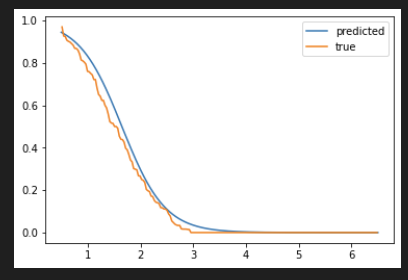

In [ ]:
model_covariates = fit_logistic_regression_demand_with_covariates(df_train)

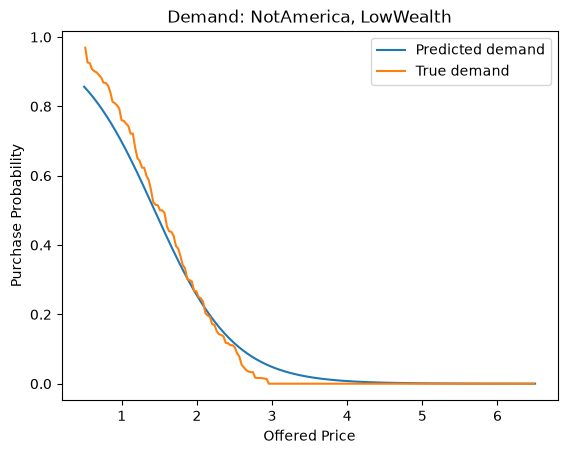

In [ ]:
predictions_not_america_low_wealth = [get_prediction_logistic_with_covariates(model_covariates, price, ['NotAmerica', 'LowWealth']) for price in prices_to_predict]

plt.plot(prices_to_predict, predictions_not_america_low_wealth, label='Predicted demand')
plt.plot(test_demand_curve_NotAmerica_LowWealth['Price_bin_mid'], test_demand_curve_NotAmerica_LowWealth['Demand_at_price'], label='True demand')
plt.xlabel('Offered Price')
plt.ylabel('Purchase Probability')
plt.title('Demand: NotAmerica, LowWealth')
plt.legend()
plt.show()

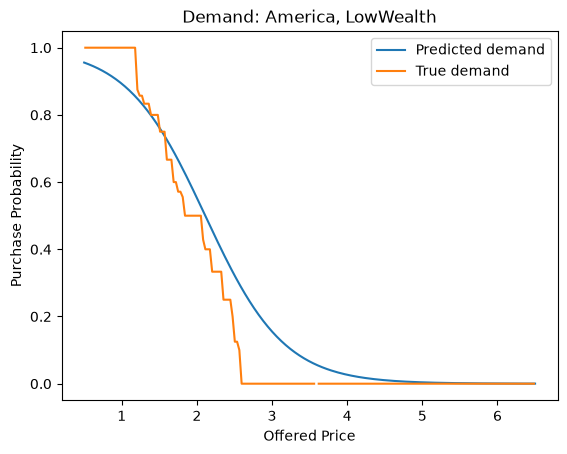

In [97]:
predictions_america_lowwealth = [get_prediction_logistic_with_covariates(model_covariates, price, ['America', 'LowWealth']) for price in prices_to_predict]

plt.plot(prices_to_predict, predictions_america_lowwealth, label='Predicted demand')
plt.plot(test_demand_curve_America_LowWealth['Price_bin_mid'], test_demand_curve_America_LowWealth['Demand_at_price'], label='True demand')
plt.xlabel('Offered Price')
plt.ylabel('Purchase Probability')
plt.title('Demand: America, LowWealth')
plt.legend()
plt.show()

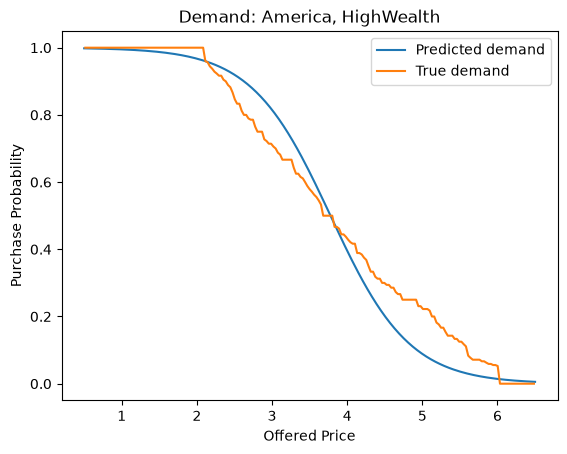

In [98]:
predictions_america_HighWealth = [get_prediction_logistic_with_covariates(model_covariates, price, ['America', 'HighWealth']) for price in prices_to_predict]

plt.plot(prices_to_predict, predictions_america_HighWealth, label='Predicted demand')
plt.plot(test_demand_curve_America_HighWealth['Price_bin_mid'], test_demand_curve_America_HighWealth['Demand_at_price'], label='True demand')
plt.xlabel('Offered Price')
plt.ylabel('Purchase Probability')
plt.title('Demand: America, HighWealth')
plt.legend()
plt.show()

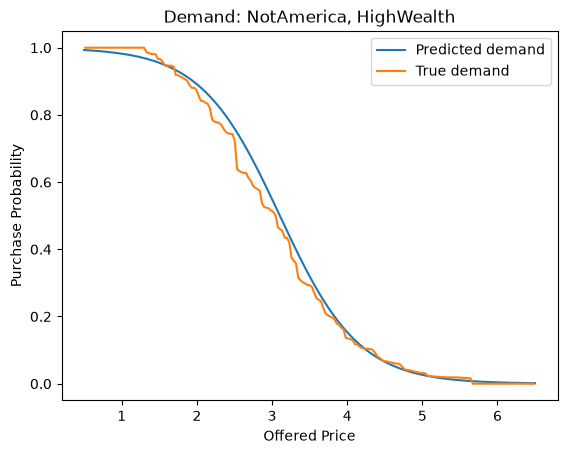

In [99]:
predictions_NotAmerica_HighWealth = [get_prediction_logistic_with_covariates(model_covariates, price, ['NotAmerica', 'HighWealth']) for price in prices_to_predict]

plt.plot(prices_to_predict, predictions_NotAmerica_HighWealth, label='Predicted demand')
plt.plot(test_demand_curve_NotAmerica_HighWealth['Price_bin_mid'], test_demand_curve_NotAmerica_HighWealth['Demand_at_price'], label='True demand')
plt.xlabel('Offered Price')
plt.ylabel('Purchase Probability')
plt.title('Demand: NotAmerica, HighWealth')
plt.legend()
plt.show()

### 2b) Pricing

<span style='color: green;'>Now, use your code from 1c to output predicted optimal prices, predicted revenue, and the actual revenue using the test data curve, for each covariate combination. Your output should have 4 rows, one for each covariate combination.</span>

For example, we got for one of the covariate combinations:

Group Not America, Low Wealth: Optimal price 1.314070, Predicted Revenue 0.913284, True revenue 0.788442

In [100]:
groups = {
    "NotAmerica, LowWealth": (predictions_not_america_low_wealth, test_demand_curve_NotAmerica_LowWealth),
    "America, LowWealth": (predictions_america_lowwealth, test_demand_curve_America_LowWealth),
    "America, HighWealth": (predictions_america_HighWealth, test_demand_curve_America_HighWealth),
    "NotAmerica, HighWealth": (predictions_NotAmerica_HighWealth, test_demand_curve_NotAmerica_HighWealth)
}

true_revenues = []

for name, (predictions, demand_curve) in groups.items():
    best_price, predicted_revenue = get_revenue_maximizing_price_and_revenue(prices_to_predict, predictions)
    matching_bin = demand_curve[(demand_curve['Price_bin_left'] < best_price) & (best_price <= demand_curve['Price_bin_right'])]
    true_demand = matching_bin['Demand_at_price'].iloc[0]
    true_revenue = best_price * true_demand
    true_revenues.append(true_revenue)

    print(name, "Price:", round(best_price, 4), "Predicted revenue:", round(predicted_revenue, 4), "True revenue:", round(true_revenue, 4))

average_true_revenue = sum(true_revenues) / 4
print("Average true revenue:", round(average_true_revenue, 4))

NotAmerica, LowWealth Price: 1.2538 Predicted revenue: 0.7356 True revenue: 0.806
America, LowWealth Price: 1.706 Predicted revenue: 1.1673 True revenue: 1.0236
America, HighWealth Price: 2.9724 Predicted revenue: 2.4457 True revenue: 2.1231
NotAmerica, HighWealth Price: 2.4296 Predicted revenue: 1.9033 True revenue: 1.8093
Average true revenue: 1.4405


<span style='color: green;'>Suppose each of the 4 covariate combinations make up an equal part of the population. What would be the resulting revenue achieved at test time if you use the optimal price for each group (so you look at their covariates, and then give them the optimal price for that group).</span>

In other words, this answer should be a single number, the mean of the true revenue of the 4 groups.

In [ ]:
1.4405

<span style='color: green;'>Comment on your outputs in no more than 3 sentences. What is the effect of using different prices for different covariate groups?</span>

With the different prices for each group, we can account for differences in behavior. The average true revenue was 1.4405, showing how personalized pricing can create revenue by changing prices in accordance with each group's demand. The predicted revenues are not always accurate, so the model may not find the true optimal price for all groups.

# Problem 3: Pricing under capacity constraints

<span style='color: green;'>AI disclosure for this problem: In the next box, describe any AI use for this problem and how it was used, or write "None".</span>

Now, we are going to build up to implementing the Bellman equation approach discussed in class, to price a single copy of an item to be sold over $T$ time periods. One potential customer arrives in each period $t=0,\ldots,T-1$. Conditional on the item still being available, the customer purchases with probability $d(p)$ when offered price $p$; this probability does not change over time. After a sale, the item is no longer available. An item left unsold at time $T$ has no salvage value. For simplicity, use `test_demand_curve` as $d(p)$ and its bin midpoints as the candidate prices for Problem 3, as specified in the next cell.

In [101]:
price_options = list(test_demand_curve.Price_bin_mid)
demand_predictions = list(test_demand_curve.Demand_at_price)

### 3a) Implementing one step of the Bellman equation

Recall the "Bellman equation" taught in class. Let $V_t$ be the maximum expected remaining total revenue from periods $t$ through $T-1$, conditional on still having the item at the start of period $t$. We set $V_T=0$. If $p_t$ is the optimal price in period $t$, then:
$$ V_t = d(p_t)p_t + (1 - d(p_t))V_{t+1}$$

<span style='color: green;'>Implement the following function that returns optimal price </span>$p_t$<span style='color: green;'> and the resulting value </span>$V_t$<span style='color: green;'>, given the demand curve and </span>$V_{t+1}$<span style='color: green;'>. </span>

For example, we find that the output of the following function call is: (2.083, 1.1922434210526316)

`get_single_step_revenue_maximizing_price_and_revenue(0, price_options, demand_predictions)`

In [102]:
def get_single_step_revenue_maximizing_price_and_revenue(Vtplus1, price_options, demand_predictions):
    pass

### 3b) Calculating prices over time


<span style='color: green;'>Implement the following function that returns a list (of length </span>$T$<span style='color: green;'>) of optimal prices for each time period, and an expected remaining total revenue </span>$V_0$<span style='color: green;'> for those prices, starting with the item unsold.</span>
    
Hint: your function should loop through each time step, _starting_ at time $t=T-1$ (the last time period, since the first time period is time $t=0$). Each iteration of the loop should call the function from part 3a. Recall that we can define $V_T = 0$, since even if the item is unsold at time $T$, we have finished trying to sell it.

In [103]:
def get_prices_over_time_and_expected_revenue(prices, demand_predictions, T):
    pass

<span style='color: green;'>Plot a line plot for your optimal prices over time when </span>$T=100$<span style='color: green;'> and </span>$T=10$<span style='color: green;'>. Also print out the expected revenue using these prices and for each </span>$T$<span style='color: green;'>. </span>

For example, when $T=100$, we find that prices[0] = 5.822, prices[90] = 4.224, and that revenue = 5.2287

### 3c) Prices over time with multiple copies

<span style='color: green;'>Now, suppose that you have </span>$K$<span style='color: green;'> copies of the item to sell over </span>$T$<span style='color: green;'> time periods. As above, one potential customer arrives per period and buys at most one item with stationary probability </span>$d(p)$<span style='color: green;'>. Let </span>$V_{t,k}$<span style='color: green;'> be the maximum expected remaining total revenue from periods </span>$t$<span style='color: green;'> through </span>$T-1$<span style='color: green;'> when </span>$k$<span style='color: green;'> items remain at the start of period </span>$t$<span style='color: green;'>. Use the boundaries </span>$V_{T,k}=0$<span style='color: green;'> for every </span>$k$<span style='color: green;'> and </span>$V_{t,0}=0$<span style='color: green;'> for every </span>$t$<span style='color: green;'>. Implement the two-dimensional dynamic program as discussed in class.</span>

<span style='color: green;'>For </span>$T=100$<span style='color: green;'> and </span>$K=5$<span style='color: green;'>, plot the optimal price </span>$p_{t,k}$<span style='color: green;'> against time </span>$t=0,\ldots,T-1$<span style='color: green;'>, with one curve for each </span>$k=1,\ldots,K$<span style='color: green;'>. Each curve shows the price at time </span>$t$<span style='color: green;'> when </span>$k$<span style='color: green;'> items remain.</span>

Hint: As in 3a and 3b, you may find it useful to first optimize the price $p_{t,k}$ given the values $V_{t+1,k}$ and $V_{t+1,k-1}$. Then, have a second function that loops through $t,k$ in an appropriate order.